# 4-1 选图与 matplotlib 基础

目标：根据问题选图，设置 Figure/Axes、标题、轴名、单位和排序。本课使用规范模拟主表，只汇总已完成订单实付金额，不含退款、不代表利润。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
setup_chinese_font(verbose=True)
orders = pd.read_csv("../data/shop/orders.csv")
products = pd.read_csv("../data/shop/products.csv")
completed = orders.loc[orders["status"].eq("已完成")].copy()
joined = completed.merge(products[["product_id", "category"]],
                         on="product_id", how="left", validate="many_to_one")
print("未关联品类：", int(joined["category"].isna().sum()))
category_sales = joined.groupby("category")["pay_amount"].sum().sort_values(ascending=False)
print(category_sales)
print("品类合计与订单合计：", category_sales.sum(), completed["pay_amount"].sum())

未关联品类： 0
category
香薰     534303.6
书籍     300468.7
帆布包    299920.9
文具     251025.0
日历     161697.6
徽章     129229.4
明信片    107725.9
Name: pay_amount, dtype: float64
品类合计与订单合计： 1784371.1 1784371.1


## 示范：Figure 是画布，Axes 是绘图区

柱图比较类别，柱长表达金额，基线从零开始。七根柱对应七个品类，不是逐笔订单。

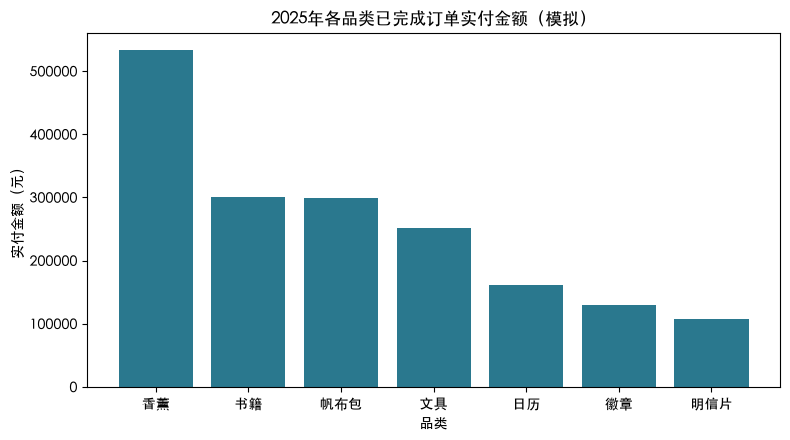

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(category_sales.index, category_sales.values, color="#2a788e")
ax.set(title="2025年各品类已完成订单实付金额（模拟）",
       xlabel="品类", ylabel="实付金额（元）")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

## 练习 1：先交付汇总列

按品类求已完成订单实付金额，降序排列。提交 Series。

In [4]:
category_sales_answer = joined.groupby("category")["pay_amount"].sum().sort_values(ascending=False)
check("4-1.1", category_sales_answer)

True

## 示范：折线按时间顺序

`month` 是月份标签，以当月第一天的日期表示，不代表订单都发生在月初。不能按金额排序后连线。

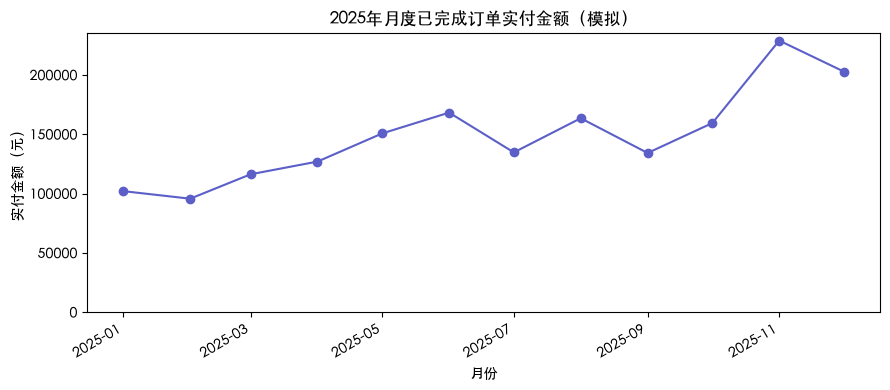

In [5]:
completed["order_time"] = pd.to_datetime(completed["order_time"])
completed["month"] = completed["order_time"].dt.to_period("M").dt.to_timestamp()
monthly = (completed.groupby("month", as_index=False)["pay_amount"]
           .sum().sort_values("month"))
fig_line, ax_line = plt.subplots(figsize=(9, 4))
ax_line.plot(monthly["month"], monthly["pay_amount"], marker="o", color="#5b5fc7")
ax_line.set(title="2025年月度已完成订单实付金额（模拟）",
            xlabel="月份", ylabel="实付金额（元）")
ax_line.set_ylim(bottom=0)
fig_line.autofmt_xdate()
fig_line.tight_layout()
plt.show()

## 练习 2：月度表

从 `completed` 独立汇总，交付 `month` 和 `pay_amount` 两列、月份日期类型、月份升序的表。

In [6]:
monthly_answer = completed.groupby("month", as_index=False)["pay_amount"].sum().sort_values("month")
check("4-1.2", monthly_answer)

True

## 练习 3：自己的柱形绘图区

用示范的 `category_sales`，新建绘图区。标题必须是“品类实付金额”，横轴“品类”，纵轴“实付金额（元）”，基线 0。提交 Axes 对象并展示图形。题目检查数据和轴标签，不限定配色。

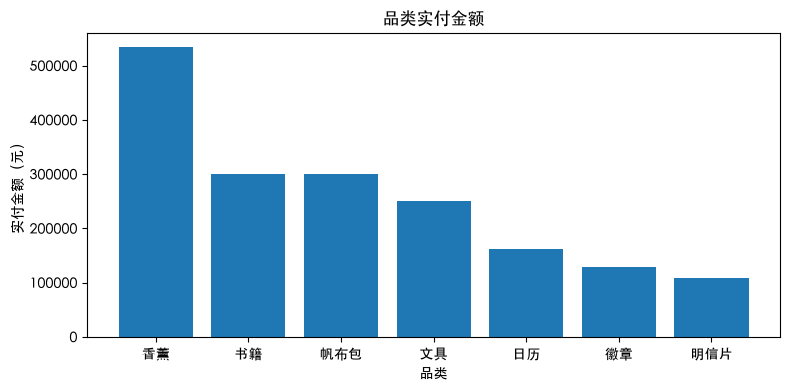

True

In [7]:
answer_fig, bar_ax_answer = plt.subplots(figsize=(8, 4))
bar_ax_answer.bar(category_sales.index, category_sales.values)
bar_ax_answer.set(title="品类实付金额", xlabel="品类", ylabel="实付金额（元）")
bar_ax_answer.set_ylim(bottom=0)
answer_fig.tight_layout()
plt.show()
check("4-1.3", bar_ax_answer)

## 练习 4：按问题选图

“各月实付金额怎样变化”适合什么图？提交“折线图”或你判断的图名，先想清排序依据。

In [8]:
chart_answer = "折线图"
check("4-1.4", chart_answer)

True

## 小测与验收

为什么不把柱形纵轴从 90% 的最小值开始？

<details><summary>参考答案</summary>柱长表达量，截断基线会夸大差异。折线如需截断也要标清范围，不能误导。</details>

验收：实际看到图；中文没有方框或缺字警告；标题、轴、单位完整；柱图从零、折线按日期。月份缺失时先分清缺采集还是零订单。模拟销售不代表利润，也不证明活动造成增长。报错先查内核、列名与关联过程，重启后从第一格运行。